Epoch 3000, Loss: 0.002676
Epoch 6000, Loss: 0.001187
Epoch 9000, Loss: 0.000759
Epoch 12000, Loss: 0.000557
Epoch 15000, Loss: 0.000440

XOR CLASSIFICATION RESULTS
Input: [0. 0.] Target: 0 Probability: 0.0005087071877654881 Prediction: 0
Input: [0. 1.] Target: 1 Probability: 0.9998502027281371 Prediction: 1
Input: [1. 0.] Target: 1 Probability: 0.9992847023530146 Prediction: 1
Input: [1. 1.] Target: 0 Probability: 0.0003836687848578163 Prediction: 0


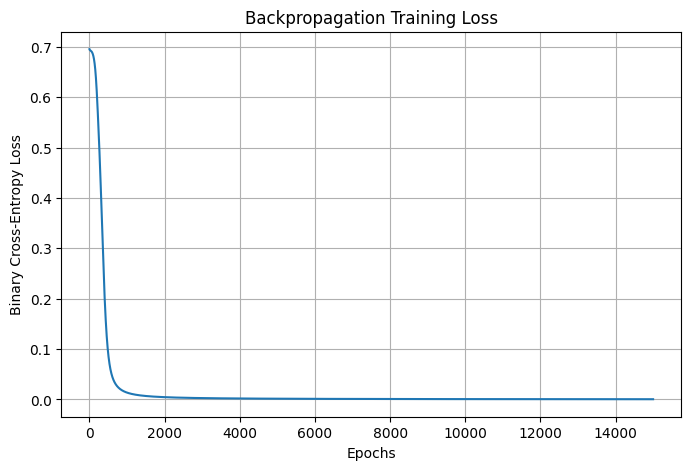

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

# 1. XOR dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

# 2. Sigmoid activation function
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

# Derivative of sigmoid
def sigmoid_derivative(x):
    return x * (1 - x)

# 3. Initialize network parameters
input_size = 2
hidden_size = 4
output_size = 1

W1 = np.random.randn(
    input_size, hidden_size
) * 0.5

b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(
    hidden_size, output_size
) * 0.5

b2 = np.zeros((1, output_size))

learning_rate = 1.0
epochs = 15000

loss_history = []

# 4. Training process
for epoch in range(epochs):

    # Forward propagation
    Z1 = np.dot(X, W1) + b1

    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2

    A2 = sigmoid(Z2)

    # Calculate binary cross-entropy loss
    epsilon = 1e-8

    loss = -np.mean(
        y * np.log(A2 + epsilon)
        + (1 - y) * np.log(1 - A2 + epsilon)
    )

    loss_history.append(loss)

    # Backpropagation
    m = X.shape[0]

    dZ2 = (A2 - y) / m

    dW2 = np.dot(A1.T, dZ2)

    db2 = np.sum(
        dZ2,
        axis=0,
        keepdims=True
    )

    dA1 = np.dot(dZ2, W2.T)

    dZ1 = (
        dA1 * sigmoid_derivative(A1)
    )

    dW1 = np.dot(X.T, dZ1)

    db1 = np.sum(
        dZ1,
        axis=0,
        keepdims=True
    )

    # Update weights and biases
    W2 -= learning_rate * dW2

    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1

    b1 -= learning_rate * db1

    if (epoch + 1) % 3000 == 0:

        print(
            f"Epoch {epoch+1}, Loss: {loss:.6f}"
        )

# 5. Final predictions
Z1 = np.dot(X, W1) + b1

A1 = sigmoid(Z1)

Z2 = np.dot(A1, W2) + b2

A2 = sigmoid(Z2)

predictions = (A2 >= 0.5).astype(int)

print("\nXOR CLASSIFICATION RESULTS")

for i in range(len(X)):

    print(
        "Input:", X[i],
        "Target:", int(y[i][0]),
        "Probability:", A2[i][0],
        "Prediction:", predictions[i][0]
    )

# 6. Plot training loss
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title(
    "Backpropagation Training Loss"
)

plt.grid()
plt.show()